# IQ Mach–Zehnder Modulator Test

This notebook verifies the dual-drive sub-MZM transfer curve and QPSK constellation generation by the IQ modulator. The implementation follows the equation in `Mach_Zehnder_Modulator_simplificado.m` and the quadrature-branch combination in `Mach_Zehnder_Modulator_DP.m`.

The test signal uses push-pull NRZ levels. Distributed electrode response can be enabled in `IQMZMParams`; it is disabled in the first curve to compare the static MZM transfer function.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.dsp.transmitter import (
    ElectricalFilterParams,
    IQMZMParams,
    dual_drive_mzm,
    generate_qpsk_symbols,
    modulate_optical_signal,
)
from src.dsp.receiver import sample_to_symbols

params = IQMZMParams()
print(f'Raiz do projeto: {PROJECT_ROOT}')
print(f'Vpi I/Q: {params.v_pi_i:.2f} V / {params.v_pi_q:.2f} V')
print(f'Inter-branch phase: {params.quadrature_phase_rad / np.pi:.2f} pi rad')

Raiz do projeto: D:\gits\PHOTONICS_2026\Codigos\python\pnn_coerente
Vpi I/Q: 3.10 V / 3.25 V
Fase entre ramos: -0.50 pi rad


## 1. Static Transfer Curve of a Dual-Drive Sub-MZM

With push-pull drive, \(U_1=V_d/2\) and \(U_2=-V_d/2\). Common phase cancels, and normalized optical power follows \(\cos^2[\pi(V_d-U_0)/(2V_\pi)]\), as given in `Mach_Zehnder_Modulator_simplificado.m`.

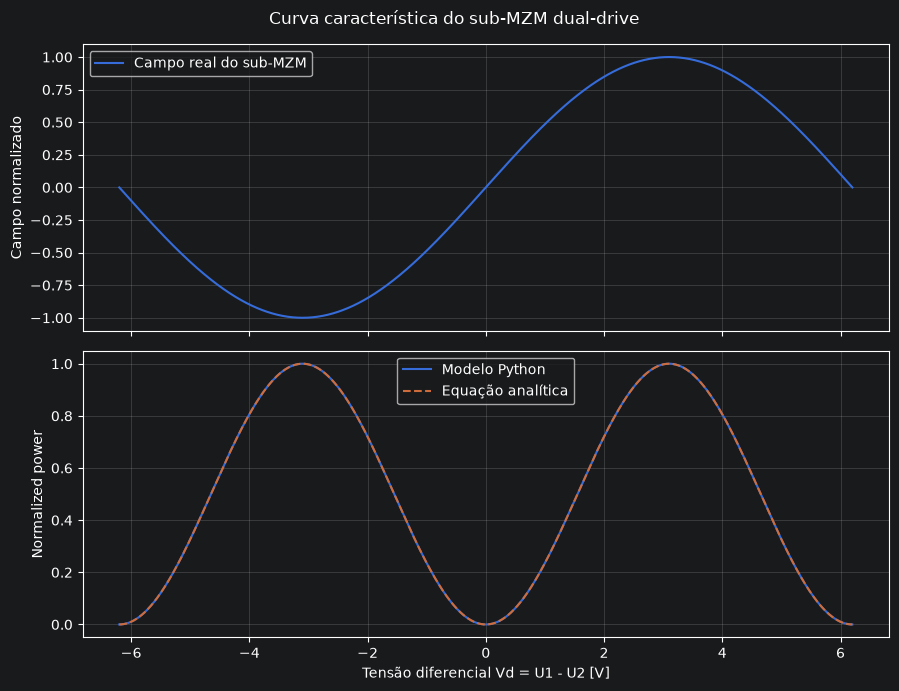

In [2]:
vpi = params.v_pi_i
u0 = params.null_bias_i
v_diff = np.linspace(-2.0 * vpi, 2.0 * vpi, 1601)

field = dual_drive_mzm(
    ein=np.ones(v_diff.size, dtype=complex),
    u1=v_diff / 2.0,
    u2=-v_diff / 2.0,
    v_pi=vpi,
    u0=u0,
)
power_normalized = np.abs(field) ** 2
power_theory = np.cos((np.pi / 2.0) * (v_diff - u0) / vpi) ** 2

assert np.allclose(power_normalized, power_theory, atol=1e-12)

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
axes[0].plot(v_diff, field.real, label='Campo real do sub-MZM')
axes[0].set_ylabel('Campo normalizado')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(v_diff, power_normalized, label='Modelo Python')
axes[1].plot(v_diff, power_theory, '--', label='Analytical equation')
axes[1].set_xlabel('Differential voltage Vd = U1 - U2 [V]')
axes[1].set_ylabel('Normalized power')
axes[1].grid(True, alpha=0.3)
axes[1].legend()
fig.suptitle('Dual-Drive Sub-MZM Transfer Characteristic')
fig.tight_layout()
plt.show()

## 2. QPSK Constellation Generation by the IQ-MZM

The two sub-MZMs generate the I and Q branches. The second branch receives the quadrature phase shift from the MATLAB DP-MZM; the electrical Q signal changes sign to preserve the I + jQ convention. The `ideal` mode remains available and is checked as a reference.

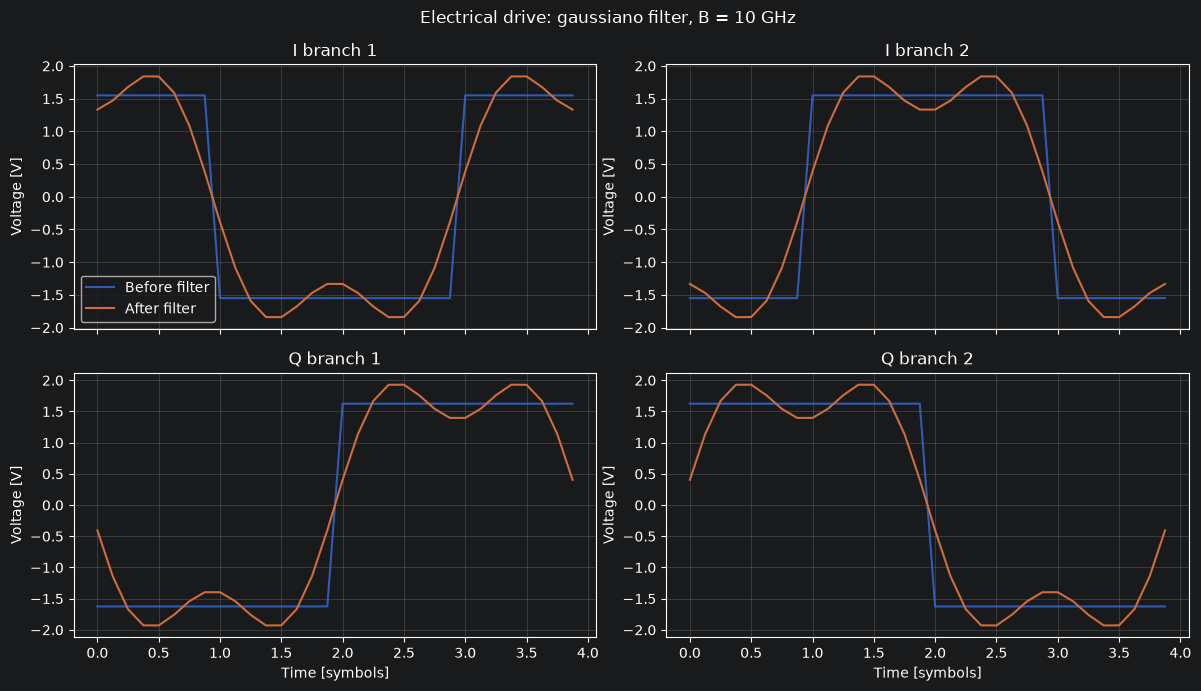

Erro máximo da constelação normalizada: 0.000e+00
Potência média IQ-MZM normalizada: 1.000 mW
Potência média sem normalização: 0.500 mW
Modo ideal padrão: mapeamento direto preservado.
Filtro Gaussiano de ordem 7: vetor finito e potência normalizada.


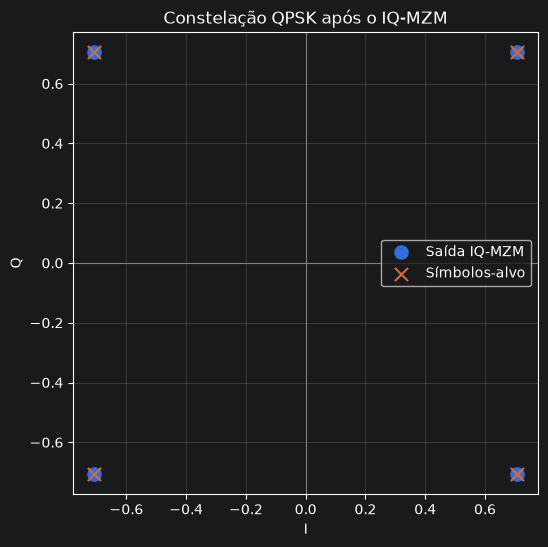

In [3]:
symbols = np.array(
    [1 + 1j, -1 + 1j, -1 - 1j, 1 - 1j],
    dtype=complex,
) / np.sqrt(2.0)

u_iq, t_iq, dt_iq = modulate_optical_signal(
    symbols,
    sps=8,
    launch_power_dbm=0.0,
    symbol_rate=10e9,
    modulator='iq_mzm',
    iq_params=params,
)
rx_iq = sample_to_symbols(u_iq, sps=8)
rx_iq_normalized = rx_iq / np.sqrt(np.mean(np.abs(rx_iq) ** 2))
max_constellation_error = np.max(np.abs(rx_iq_normalized - symbols))
mean_output_power_w = np.mean(np.abs(u_iq) ** 2)

assert np.allclose(rx_iq_normalized, symbols, atol=1e-12)
assert np.isclose(mean_output_power_w, 1e-3, rtol=1e-12)

u_iq_raw, _, _ = modulate_optical_signal(
    symbols,
    sps=8,
    launch_power_dbm=0.0,
    symbol_rate=10e9,
    modulator='iq_mzm',
    iq_params=params,
    normalize_output_power=False,
)
raw_output_power_w = np.mean(np.abs(u_iq_raw) ** 2)
assert np.isclose(raw_output_power_w, 0.5e-3, rtol=1e-12)

u_ideal, _, _ = modulate_optical_signal(
    symbols,
    sps=8,
    launch_power_dbm=0.0,
    symbol_rate=10e9,
)
ideal_expected = np.repeat(symbols, 8)
ideal_expected *= np.sqrt(1e-3 / np.mean(np.abs(ideal_expected) ** 2))
assert np.allclose(u_ideal, ideal_expected, atol=1e-15)

# Gaussian low-pass filter: B is the bandwidth at −3 dB.
# Here B = Rs = 10 GBaud; adjust it to match the driver bandwidth being modeled.
filter_params = ElectricalFilterParams(
    tipo='gaussiano',
    largura_banda_hz=10e9,
    ordem=7,
)
u_iq_filtered, _, _ = modulate_optical_signal(
    symbols,
    sps=8,
    launch_power_dbm=0.0,
    symbol_rate=10e9,
    modulator='iq_mzm',
    iq_params=params,
    filter_params=filter_params,
    plot_filter=True,
)
assert np.all(np.isfinite(u_iq_filtered))
assert np.isclose(np.mean(np.abs(u_iq_filtered) ** 2), 1e-3, rtol=1e-12)

print(f'Maximum normalized-constellation error: {max_constellation_error:.3e}')
print(f'Normalized IQ-MZM mean power: {mean_output_power_w * 1e3:.3f} mW')
print(f'Mean power without normalization: {raw_output_power_w * 1e3:.3f} mW')
print('Default ideal mode: direct mapping preserved.')
print('Seventh-order Gaussian filter: finite vector and normalized power.')

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(rx_iq_normalized.real, rx_iq_normalized.imag, s=90, label='IQ-MZM output')
ax.scatter(symbols.real, symbols.imag, marker='x', s=90, label='Target symbols')
ax.axhline(0, color='gray', linewidth=0.8)
ax.axvline(0, color='gray', linewidth=0.8)
ax.set_xlabel('I')
ax.set_ylabel('Q')
ax.set_title('QPSK Constellation after the IQ-MZM')
ax.grid(True, alpha=0.3)
ax.axis('equal')
ax.legend()
plt.show()

## Interpretation

The first figure directly compares the numerical response with the MATLAB cosine curve. For the IQ-MZM, the filter plot compares the four electrical drives before and after the seventh-order Gaussian low-pass filter (B = 10 GHz). The constellation also verifies the four QPSK symbols. Mean power remains normalized to the requested launch power; to represent intrinsic splitter/combiner loss, call `modulate_optical_signal(..., normalize_output_power=False)`.